In [1]:
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

SCHEME = "LL-SG"
RESULTS_DIR = Path("./results")

def load_results(suffix: str) -> pl.DataFrame:
    dfs = []
    for f in RESULTS_DIR.iterdir():
        if not (f.is_file() and f.name.endswith(f"_{suffix}.csv")):
            continue
        parts = f.name.split("_")
        c_idx = next(i for i, p in enumerate(parts) if p.startswith("c") and p[1:].isdigit())
        scheme = "_".join(parts[:c_idx])
        if scheme != SCHEME:
            continue
        df = pl.read_csv(str(f))
        n_clients = int(parts[c_idx][1:])
        df = df.with_columns(pl.lit(scheme).alias("scheme"), pl.lit(n_clients).alias("nClients"))
        dfs.append(df)
    return pl.concat(dfs) if dfs else pl.DataFrame()

## Analytical Reference Values

- GPU: RTX 5060 modelled with 5 DVFS operating points.
- Workload: YOLOv8n (8.7 GFLOP, 60 KB input, 1 KB output).
- Topology: Point-to-point, 1 Gbps / 2 μs per link.
- Scheme: LL-SG

In [2]:
PEAK_RATE = 19.2e12       # FP32 FLOPS
MIN_FREQ = 2.280e9       # Hz
MAX_FREQ = 2.50e9       # Hz
EFFICIENCY = 0.075
MEM_BW = 448e9            # bytes/s
TRANSFER_BW = 32e9        # bytes/s
STATIC_POWER = 9.0        # W
C_EFF = 1.94e-8           # F

OPP_BASE = (2.280e9, 0.880)  # (freq, voltage)

# Workload
COMPUTE_DEMAND = 8.7e9    # FLOP
INPUT_SIZE = 60_000       # bytes
OUTPUT_SIZE = 1_000       # bytes
FRAME_RATE = 30.0
SIM_TIME = 20.0
TOTAL_TIME = SIM_TIME + 2.0

RATE_AT_BASE = PEAK_RATE * (MIN_FREQ / MAX_FREQ)
EFF_RATE = RATE_AT_BASE * EFFICIENCY

def processing_time(eff_rate):
    return INPUT_SIZE / TRANSFER_BW + COMPUTE_DEMAND / eff_rate + OUTPUT_SIZE / TRANSFER_BW

T_PROC = processing_time(EFF_RATE)
T_COMPUTE = COMPUTE_DEMAND / EFF_RATE

def dynamic_power(opp):
    f, v = opp
    return C_EFF * v**2 * f

P_DYN = dynamic_power(OPP_BASE)

print(f"Effective rate:  {EFF_RATE:.4e} FLOPS")
print(f"Processing time: {T_PROC*1e3:.4f} ms")
print(f"Compute time:    {T_COMPUTE*1e3:.4f} ms")
print(f"P_dynamic:       {P_DYN:.2f} W")
print(f"P_static:        {STATIC_POWER:.1f} W")

Effective rate:  1.3133e+12 FLOPS
Processing time: 6.6265 ms
Compute time:    6.6246 ms
P_dynamic:       34.25 W
P_static:        9.0 W


In [3]:
frames = load_results("frames")
energy = load_results("energy")
completed = frames.filter(pl.col("event").is_in(["processed", "violated"]))

## 1. No drops, rejections, or violations under no contention

In [4]:
outcomes = frames.select(
    (pl.col("event") == "sent").sum().alias("sent"),
    (pl.col("event") == "processed").sum().alias("processed"),
    (pl.col("event") == "violated").sum().alias("violated"),
    (pl.col("event") == "dropped").sum().alias("dropped"),
    (pl.col("event") == "rejected").sum().alias("rejected"),
)
print(outcomes)

shape: (1, 5)
┌──────┬───────────┬──────────┬─────────┬──────────┐
│ sent ┆ processed ┆ violated ┆ dropped ┆ rejected │
│ ---  ┆ ---       ┆ ---      ┆ ---     ┆ ---      │
│ u64  ┆ u64       ┆ u64      ┆ u64     ┆ u64      │
╞══════╪═══════════╪══════════╪═════════╪══════════╡
│ 5690 ┆ 5690      ┆ 0        ┆ 0       ┆ 0        │
└──────┴───────────┴──────────┴─────────┴──────────┘


## 2. Determinism across seeds

With constant workload parameters, all 10 seeds should produce identical per-frame metrics, confirming no unintended randomness.

In [7]:
compute_std = completed["compute_ms"].std()
comm_std = completed["comm_ms"].std()
queue_std = completed["queue_ms"].std()

print(f"compute_ms std across all frames/seeds: {compute_std:.6f}")
print(f"comm_ms    std across all frames/seeds: {comm_std:.6f}")
print(f"queue_ms   std across all frames/seeds: {queue_std:.6f}")

compute_ms std across all frames/seeds: 0.000000
comm_ms    std across all frames/seeds: 0.000017
queue_ms   std across all frames/seeds: 0.000000


## 3. Scheme equivalence under no contention

With a single client and no contention, RR-NS and LL-NS produce identical per-frame metrics and energy. LL-SG diverges because its keeps the backend at the base OPP instead of scaling up.

In [6]:
def load_all(suffix):
    dfs = []
    for f in RESULTS_DIR.iterdir():
        if not (f.is_file() and f.name.endswith(f"_{suffix}.csv")):
            continue
        parts = f.name.split("_")
        c_idx = next(i for i, p in enumerate(parts) if p.startswith("c") and p[1:].isdigit())
        scheme = "_".join(parts[:c_idx])
        df = pl.read_csv(str(f))
        n_clients = int(parts[c_idx][1:])
        df = df.with_columns(pl.lit(scheme).alias("scheme"), pl.lit(n_clients).alias("nClients"))
        dfs.append(df)
    return pl.concat(dfs) if dfs else pl.DataFrame()

all_frames = load_all("frames")
all_energy = load_all("energy")
completed_all = all_frames.filter(pl.col("event").is_in(["processed", "violated"]))

frames_by_scheme = (
    completed_all
    .group_by("scheme")
    .agg(
        pl.col("compute_ms").mean().alias("compute_ms"),
        pl.col("queue_ms").mean().alias("queue_ms"),
        pl.col("comm_ms").mean().alias("comm_ms"),
        pl.col("latency_ms").mean().alias("latency_ms"),
    )
    .sort("scheme")
)
print(frames_by_scheme)

energy_by_scheme = (
    all_energy
    .group_by(["scheme", "backend_id"])
    .agg(pl.col("total_energy_j").mean().alias("energy_j"))
    .sort(["scheme", "backend_id"])
)
print(energy_by_scheme)

shape: (3, 5)
┌────────┬────────────┬──────────┬──────────┬────────────┐
│ scheme ┆ compute_ms ┆ queue_ms ┆ comm_ms  ┆ latency_ms │
│ ---    ┆ ---        ┆ ---      ┆ ---      ┆ ---        │
│ str    ┆ f64        ┆ f64      ┆ f64      ┆ f64        │
╞════════╪════════════╪══════════╪══════════╪════════════╡
│ LL-NS  ┆ 5.4804     ┆ 0.0      ┆ 1.029201 ┆ 6.509601   │
│ LL-SG  ┆ 6.6265     ┆ 0.0      ┆ 1.029201 ┆ 7.655701   │
│ RR-NS  ┆ 5.4804     ┆ 0.0      ┆ 1.029201 ┆ 6.509601   │
└────────┴────────────┴──────────┴──────────┴────────────┘
shape: (6, 3)
┌────────┬────────────┬────────────┐
│ scheme ┆ backend_id ┆ energy_j   │
│ ---    ┆ ---        ┆ ---        │
│ str    ┆ i64        ┆ f64        │
╞════════╪════════════╪════════════╡
│ LL-NS  ┆ 0          ┆ 376.604116 │
│ LL-NS  ┆ 1          ┆ 198.0      │
│ LL-SG  ┆ 0          ┆ 327.114834 │
│ LL-SG  ┆ 1          ┆ 198.0      │
│ RR-NS  ┆ 0          ┆ 287.459004 │
│ RR-NS  ┆ 1          ┆ 287.145112 │
└────────┴────────────┴───────────

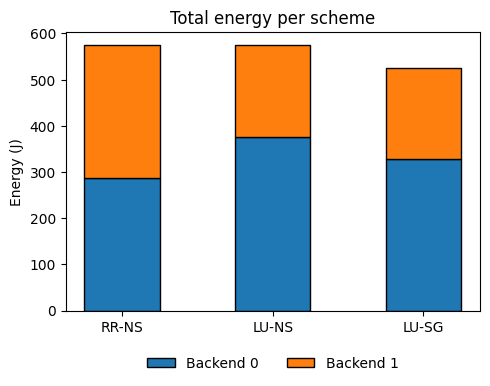

In [7]:
SCHEMES = ["RR-NS", "LL-NS", "LL-SG"]

backend_energy = (
    all_energy.filter(pl.col("scheme").is_in(SCHEMES))
    .group_by(["scheme", "backend_id"])
    .agg(pl.col("total_energy_j").mean().alias("energy_j"))
    .sort(["scheme", "backend_id"])
)
backend_ids = sorted(backend_energy["backend_id"].unique().to_list())

fig, ax = plt.subplots(figsize=(5, 4))
x = np.arange(len(SCHEMES))
width = 0.5
bottom = np.zeros(len(SCHEMES))

for bid in backend_ids:
    energies = []
    for scheme in SCHEMES:
        val = backend_energy.filter(
            (pl.col("scheme") == scheme) & (pl.col("backend_id") == bid)
        )["energy_j"]
        energies.append(val[0] if len(val) else 0.0)
    energies = np.array(energies)
    ax.bar(x, energies, width, bottom=bottom, label=f"Backend {bid}", edgecolor="black")
    bottom += energies

ax.set_xticks(x)
ax.set_xticklabels(SCHEMES)
ax.set_ylabel("Energy (J)")
ax.set_title("Total energy per scheme")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12),
          ncol=2, frameon=False)
fig.tight_layout()
plt.show()

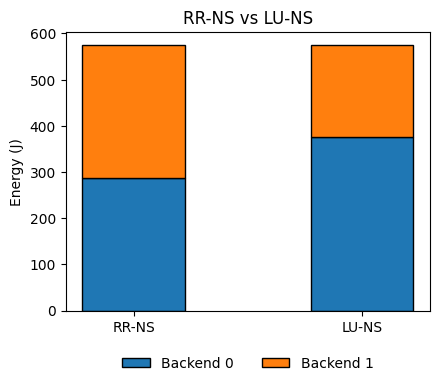

In [8]:
SCHEMES_EQ = ["RR-NS", "LL-NS"]

subset_energy = (
    all_energy.filter(pl.col("scheme").is_in(SCHEMES_EQ))
    .group_by(["scheme", "backend_id"])
    .agg(pl.col("total_energy_j").mean().alias("energy_j"))
    .sort(["scheme", "backend_id"])
)
backend_ids = sorted(subset_energy["backend_id"].unique().to_list())

fig, ax = plt.subplots(figsize=(4.5, 4))
x = np.arange(len(SCHEMES_EQ))
width = 0.45
bottom = np.zeros(len(SCHEMES_EQ))

for bid in backend_ids:
    energies = []
    for scheme in SCHEMES_EQ:
        val = subset_energy.filter(
            (pl.col("scheme") == scheme) & (pl.col("backend_id") == bid)
        )["energy_j"]
        energies.append(val[0] if len(val) else 0.0)
    energies = np.array(energies)
    ax.bar(x, energies, width, bottom=bottom, label=f"Backend {bid}", edgecolor="black")
    bottom += energies

ax.set_xticks(x)
ax.set_xticklabels(SCHEMES_EQ)
ax.set_ylabel("Energy (J)")
ax.set_title("RR-NS vs LL-NS")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12),
          ncol=2, frameon=False)
fig.tight_layout()
plt.show()